# 01 – Exploration des DVF (Rhône, 2024)
Objectif : comprendre la structure des données et lister les problèmes de qualité avant le nettoyage.

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from dvf_analyse.data_loading import charger_dossier

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

df = charger_dossier("data/raw")
df.head()

,id_mutation,date_mutation,numero_disposition,nature_mutation,valeur_fonciere,code_postal,code_commune,nom_commune,code_departement,id_parcelle,type_local,surface_reelle_bati,nombre_pieces_principales,surface_terrain,longitude,latitude,annee_fichier
0,2024-809977,2024-01-05,1,Vente,350000.0,69410,69040,Champagne-au-Mont-d'Or,69,69040000AE0256,Appartement,69.0,3.0,NaN,4.794854,45.791146,2024
1,2024-809977,2024-01-05,1,Vente,350000.0,69410,69040,Champagne-au-Mont-d'Or,69,69040000AE0256,Dépendance,NaN,0.0,NaN,4.794854,45.791146,2024
2,2024-809977,2024-01-05,1,Vente,350000.0,69410,69040,Champagne-au-Mont-d'Or,69,69040000AE0256,Dépendance,NaN,0.0,NaN,4.794854,45.791146,2024
3,2024-809978,2024-01-04,1,Vente,74800.0,69400,69264,Villefranche-sur-Saône,69,69264000AB0030,Dépendance,NaN,0.0,NaN,4.708770,45.997546,2024
4,2024-809978,2024-01-04,1,Vente,74800.0,69400,69264,Villefranche-sur-Saône,69,69264000AB0030,Appartement,35.0,1.0,NaN,4.708770,45.997546,2024


### tailles et types

In [11]:
print(f"{df.shape[0]:,} lignes, {df.shape[1]} colonnes")
df.info(memory_usage="deep")

75,985 lignes, 17 colonnes
<class 'pandas.DataFrame'>
RangeIndex: 75985 entries, 0 to 75984
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   id_mutation                75985 non-null  string        
 1   date_mutation              75985 non-null  datetime64[us]
 2   numero_disposition         75985 non-null  int64         
 3   nature_mutation            75985 non-null  category      
 4   valeur_fonciere            75703 non-null  float64       
 5   code_postal                75216 non-null  string        
 6   code_commune               75985 non-null  string        
 7   nom_commune                75985 non-null  string        
 8   code_departement           75985 non-null  string        
 9   id_parcelle                75985 non-null  string        
 10  type_local                 59890 non-null  category      
 11  surface_reelle_bati        30318 non-null  float64 

### Valeurs manquantes

In [43]:
manquantes = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
manquantes.to_frame("% manquant")

,% manquant
surface_terrain,61.6
surface_reelle_bati,60.1
nombre_pieces_principales,21.3
type_local,21.2
longitude,2.2
latitude,2.2
code_postal,1.0
valeur_fonciere,0.4
id_mutation,0.0
code_departement,0.0


`surface_terrain` est vide à 61.6 % : c'est cohérent avec la structure des
données, car elle n'est pas renseignée pour les appartements (vérifié :
Y % de vides pour les appartements contre Z % pour les maisons).
→ Décision : ne pas l'imputer, l'utiliser seulement pour les maisons.

`surface_reelle_bati` est vide à 60.1 %. Ce taux n'est pas normal pour des
logements : vérification par type de local → les vides se concentrent sur
[...].
→ Décision : [filtrer les lignes sans bâti / agréger par transaction...].

`valeur_fonciere` est vide pour 0,4 % des lignes (57 transactions). Ces lignes
correspondent à 8 appartements/maison.
→ Décision : Exclure ces transactions car elles fausseront le résultat de l'étude.

In [ ]:
sans_prix = df[df["valeur_fonciere"].isna()]
print(sans_prix["nature_mutation"].value_counts())
print(sans_prix["type_local"].value_counts(dropna=False))
print(sans_prix["id_mutation"].nunique(), "transactions concernées")

nature_mutation
Vente                                 40786
Vente en l'état futur d'achèvement     4266
Echange                                 513
Adjudication                             57
Vente terrain à bâtir                    43
Expropriation                             2
Name: count, dtype: int64
type_local
Dépendance                                  29430
NaN                                         16095
Local industriel. commercial ou assimilé      138
Appartement                                     4
Maison                                          0
Name: count, dtype: int64
23134 transactions concernées


In [45]:
cible = sans_prix[
    (sans_prix["nature_mutation"] == "Vente")
    & (sans_prix["type_local"].isin(["Maison", "Appartement"]))
]
print(cible["id_mutation"].nunique(), "ventes de maisons/appartements sans prix")

8 ventes de maisons/appartements sans prix


In [49]:
logements = df[df["type_local"].isin(["Maison", "Appartement"])]
print(f"{len(logements):,} lignes de logements")
print(f"{logements['surface_reelle_bati'].isna().sum()} sans surface bâtie")
print(f"{(logements['surface_reelle_bati'] == 0).sum()} avec surface = 0")
ids = logements.loc[logements["surface_reelle_bati"].isna(), "id_mutation"]
df[df["id_mutation"].isin(ids)]

25,307 lignes de logements
4 sans surface bâtie
0 avec surface = 0


,id_mutation,date_mutation,numero_disposition,nature_mutation,valeur_fonciere,code_postal,code_commune,nom_commune,code_departement,id_parcelle,type_local,surface_reelle_bati,nombre_pieces_principales,surface_terrain,longitude,latitude,annee_fichier
5346,2024-812092,2024-02-28,1,Vente,118000.0,69270,69068,Couzon-au-Mont-d'Or,69,690680000C0365,Appartement,40.0,2.0,NaN,4.830520,45.839851,2024
5347,2024-812092,2024-02-28,1,Vente,118000.0,69270,69068,Couzon-au-Mont-d'Or,69,690680000C0365,Appartement,NaN,NaN,NaN,4.830520,45.839851,2024
7636,2024-813008,2024-03-25,1,Vente,260000.0,69280,69127,Marcy-l'Étoile,69,69127000AI0200,Appartement,NaN,NaN,NaN,4.719999,45.782300,2024
7637,2024-813008,2024-03-25,1,Vente,260000.0,69280,69127,Marcy-l'Étoile,69,69127000AI0200,Dépendance,NaN,0.0,NaN,4.719999,45.782300,2024
9952,2024-813877,2024-04-02,1,Vente,135000.0,69930,69220,Saint-Laurent-de-Chamousset,69,692200000F1116,Appartement,NaN,NaN,NaN,4.464253,45.737248,2024
65929,2024-835675,2024-10-09,1,Vente,349750.0,69003,69383,Lyon 3e Arrondissement,69,69383000DO0019,Dépendance,NaN,0.0,NaN,4.870870,45.754510,2024
65930,2024-835675,2024-10-09,1,Vente,349750.0,69003,69383,Lyon 3e Arrondissement,69,69383000DO0019,Appartement,NaN,NaN,NaN,4.870870,45.754510,2024
65931,2024-835675,2024-10-09,1,Vente,349750.0,69003,69383,Lyon 3e Arrondissement,69,69383000DO0019,Appartement,64.0,3.0,NaN,4.870870,45.754510,2024


### Doublons exactes

In [13]:
print(f"Doublons exacts : {df.duplicated().sum():,}")

Doublons exacts : 16,130


### Structure par transaction

In [14]:
nb_mutations = df["id_mutation"].nunique()
print(f"{len(df):,} lignes pour {nb_mutations:,} transactions")

lignes_par_mutation = df.groupby("id_mutation").size()
print(lignes_par_mutation.describe())

75,985 lignes pour 29,295 transactions
count    29295.000000
mean         2.593787
std          5.133661
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max        406.000000
dtype: float64


### Valeurs foncières manquantes

In [15]:
prix_par_mutation = df.groupby("id_mutation")["valeur_fonciere"].first()
print(f"Transactions sans prix : {prix_par_mutation.isna().sum():,}")

Transactions sans prix : 57


### Répartitions

In [16]:
print(df["nature_mutation"].value_counts(dropna=False))
print()
print(df["type_local"].value_counts(dropna=False))

nature_mutation
Vente                                 69481
Vente en l'état futur d'achèvement     5681
Echange                                 632
Adjudication                            135
Vente terrain à bâtir                    54
Expropriation                             2
Name: count, dtype: int64

type_local
Dépendance                                  29430
Appartement                                 18508
NaN                                         16095
Maison                                       6799
Local industriel. commercial ou assimilé     5153
Name: count, dtype: int64


### Statistiques depressives

In [17]:
df[["valeur_fonciere", "surface_reelle_bati", "nombre_pieces_principales", "surface_terrain"]].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).round(1)

,valeur_fonciere,surface_reelle_bati,nombre_pieces_principales,surface_terrain
count,75703.0,30318.0,59838.0,29194.0
mean,662704.7,108.7,1.4,2096.3
std,2540025.0,607.9,1.9,53393.1
min,1.0,1.0,0.0,1.0
1%,1.0,10.0,0.0,3.0
25%,142000.0,44.0,0.0,220.0
50%,249000.0,67.0,0.0,546.0
75%,426150.0,94.0,3.0,1306.0
99%,10966697.0,757.5,6.0,19277.7
max,118000000.0,61640.0,28.0,7700000.0


### Valeurs suspectes

In [18]:
print("Prix <= 1 000 € :", (df["valeur_fonciere"] <= 1000).sum())
print("Surface bâtie > 500 m² :", (df["surface_reelle_bati"] > 500).sum())
print("Surface bâtie = 0 :", (df["surface_reelle_bati"] == 0).sum())

Prix <= 1 000 € : 1884
Surface bâtie > 500 m² : 455
Surface bâtie = 0 : 0


### Transactions par mois

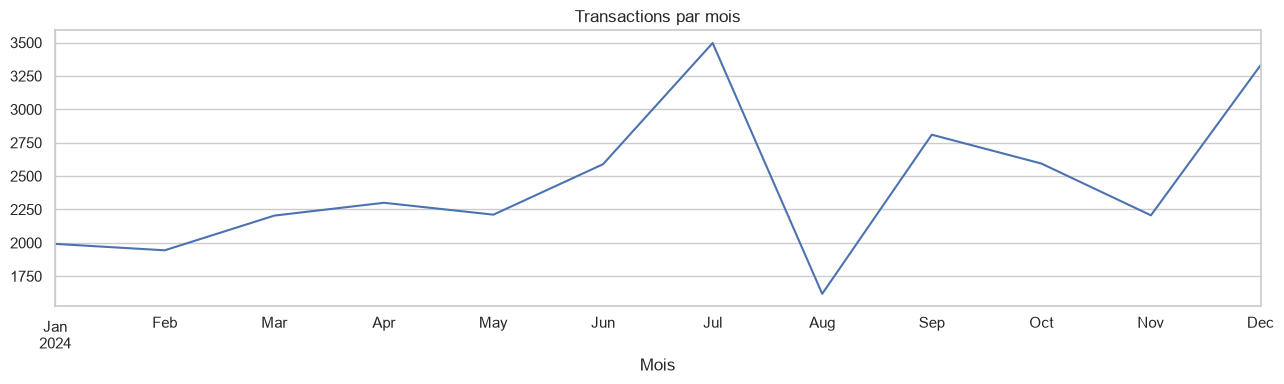

In [26]:
mutations = df.drop_duplicates("id_mutation")

par_mois = mutations.set_index("date_mutation").resample("MS").size()

fig, axes = plt.subplots(1, figsize=(13, 4))
par_mois.plot(ax=axes, title="Transactions par mois")
axes.set_xlabel("Mois")
plt.tight_layout()
plt.show()

### Distribution des prix (échelle logarithmique)

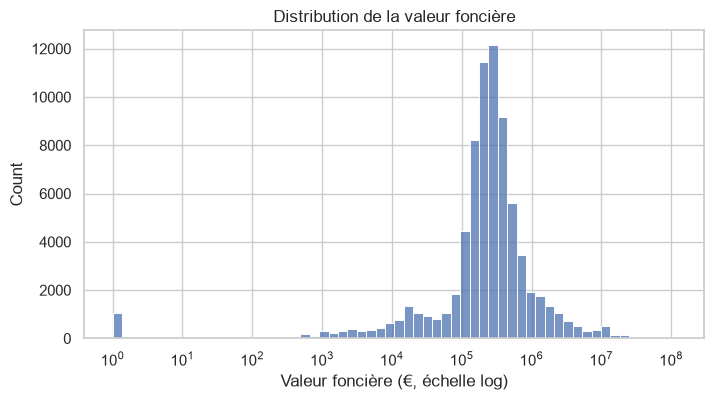

In [27]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df["valeur_fonciere"].dropna(), log_scale=True, bins=60, ax=ax)
ax.set_title("Distribution de la valeur foncière")
ax.set_xlabel("Valeur foncière (€, échelle log)")
plt.show()

## Problèmes de qualité repérés


- [1884] **Prix aberrants.** X lignes ≤ 1 000 €.
  → Un bien à 1 € est presque toujours une donation, un échange ou une
  erreur, pas un prix de marché.
  → Décision : exclure les transactions sous un seuil (à fixer en regardant
  la distribution).

- [130000] **Valeurs manquantes.** `surface_terrain` manque à 61 %, mais c'est
  structurel (appartements) pareil pour `surface_reelle_battie`. Cependant on observe 0.4% de valeur fonciere non renseignée.
  → Décision : ne pas imputer ; utiliser `surface_reelle_bati` pour les
  appartements.

- [x] **Doublons exacts.** X lignes.
  → Décision : les supprimer.

- [x] **Types de biens.** Dépendances et locaux commerciaux présents.
  → Décision : ne garder que Maison et Appartement.

- [x] **Natures de mutation.** Ventes, VEFA, adjudications...
  → Décision : ne garder que « Vente », car les autres ont des prix
  non comparables.